# Statistical Arbitrage on S&P 500 Equities — Part 1: Walk-forward Pairs Trading
### Engle-Granger cointegration, hedge ratio held fixed out-of-sample, half-life driven trading

This notebook builds a walk-forward pairs-trading backtester on S&P 500 stocks, following `phases.txt`
(Phases 0–6, plus the robustness checks of Phase 9 and the conclusions of Phase 10 for the pairs book).
Part 2 (`02_cross_sectional_residual.ipynb`) extends the framework to a cross-sectional PCA residual model.

Every phase has the same layout:

1. **What we do and why** (markdown, read this first),
2. **the code**, kept short and commented,
3. **a check or a picture** so you can see the step worked.

**How to read the results.** All parameters were chosen on a *development* period (**2011–2018**). The
**2019–2026** period is a *holdout*: it was only used to report results, never to choose parameters. When the
two periods agree, the result is more likely to be real. Every number in this notebook is out-of-sample in
the walk-forward sense: positions on day *t* use only data up to day *t*.

### Results at a glance (2011–2026, out-of-sample, 5 bps per dollar traded + 50 bps/yr borrow)

| | Textbook rules (previous version) on the same data | **This notebook** |
|---|---|---|
| Net Sharpe, full period | −0.25 | **+0.50** |
| Net Sharpe, development 2011–18 / holdout 2019–26 | −0.41 / −0.10 | **+0.44 / +0.56** |
| Gross Sharpe (before costs) | +0.17 | +1.14 |
| Net return / yr (at 66% average gross exposure) | −0.8% | +1.6% |
| Beta to SPY | | +0.04 |
| Max drawdown (net) | | −6.3% |
| Break-even cost per dollar traded | | ~9 bps |

The strategy has real predictive power, and a random signal with the same trading frequency earns nothing. It
is profitable net of realistic costs in both the development and holdout periods. Every number is re-computed
below. The conclusions section discusses the caveats: 2020 contributes a large share of the profit, and results
depend on formation length and execution timing.

## What was wrong with the previous version (and what this notebook changes)

The previous notebooks (v1 and v2, now removed from the repo) implemented the textbook version of this strategy
and lost money. These are the problems that mattered. Phase 9.1 switches the fixes on one at a time on the same
data, so you can see what each one is worth (the biggest single gain comes from #3).

| # | Problem in the previous version | Why it hurts | Fix here |
|---|---|---|---|
| 1 | **Wrong critical values for the cointegration test.** v1 ran `adfuller` on the OLS residual and used its p-value. | The OLS slope is chosen to make the residual look as stationary as possible, so the ordinary Dickey-Fuller table is too lenient: ~18% of pairs "pass" at 5% instead of ~7%. The *ranking* of pairs is unchanged, but the test no longer tells you honestly how many genuine pairs exist. | Same ADF regression, but with the **Engle-Granger (MacKinnon, N=2) critical values**, which is what `statsmodels.coint` does. |
| 2 | **Pairs searched inside broad GICS sectors** (e.g. Boeing vs Waste Management, both "Industrials"). | Cointegration between economically unrelated firms is mostly coincidence and does not persist out of sample. | Pairs only inside the same **GICS sub-industry** (e.g. KO/PEP, XOM/CVX, DUK/SO). |
| 3 | **Spread z-score used the formation-window mean, frozen for 3 months.** | v1's own diagnosis: out of sample the spread's level drifted ~1.5σ away from the formation mean, so half the trades hit the −3σ stop and only 7% reverted. | Hedge ratio stays frozen (as in the CV), but the spread's **equilibrium level is tracked with a rolling window whose length is set by the half-life** (2 × half-life). |
| 4 | **Hedge ratio estimated, then ignored for sizing.** v1 traded equal dollars on both legs even when β = 0.12. | The portfolio actually traded was *not* the stationary spread that was tested. | Legs are sized with the frozen hedge ratio: $1 of A against $β of B (normalised). The book stays close to dollar-neutral and has ~0 market beta (checked below). |
| 5 | **Concentration.** The same stock appeared in many pairs (Boeing was in 6 of the top 15 pairs in 2019). | One idiosyncratic shock (737 MAX) hits many "independent" bets at once. | **Each stock can be in at most one pair** per window. |
| 6 | **Book mostly in cash** (20 slots, 3.6 pairs open on average) and pairs ranked by smallest in-sample p-value (the most over-fitted). | Few, correlated bets → noisy, low Sharpe. | 40 slots, one pair per stock, and **capital per pair ∝ 1/√half-life** (faster mean reversion → more capital). |

---
## Phase 0 — Setup

**Every tunable number lives in this one cell.** If you want to change anything, change it here and re-run the
notebook top to bottom.

A word on **costs**, because they decide whether a stat-arb strategy makes money:

* Each time we trade $1 of stock we pay **commission + half the bid-ask spread + slippage**. For S&P 500 names
  during 2011–2026, quoted half-spreads are typically 1–2 bps and institutional commissions well under 1 bp.
  We use **1 + 2 + 2 = 5 bps per dollar traded**, which is deliberately on the conservative side.
  (the previous version used 10 bps, which is more like small-cap or 2000s costs; the robustness section shows results at 0, 3, 5 and 10 bps.)
* Short positions pay a **borrow fee**: 50 bps per year for general-collateral S&P 500 names.

In [1]:
from pathlib import Path
from itertools import combinations
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.adfvalues import mackinnonp
from statsmodels.tsa.stattools import coint

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------- data ----------------
DATA_DIR = Path("data")
DATA_START = "2010-01-01"
MAX_MISSING_PCT = 0.05          # drop tickers missing more than 5% of days
DEV_END = "2018-12-31"          # parameters chosen on <= this date; later dates are the holdout
TRADING_DAYS = 252

# ---------------- walk-forward windows (trading days) ----------------
FORMATION_WINDOW = 252          # 1 year of history to form pairs
TRADING_WINDOW = 63             # 1 quarter traded out-of-sample, then everything is re-estimated

# ---------------- Phase 2: pair formation ----------------
COINT_PVALUE = 0.05             # Engle-Granger test level
MIN_HALF_LIFE, MAX_HALF_LIFE = 1, 40   # days; outside this range a spread is too noisy / too slow to trade
MAX_PAIRS = 40                  # pair slots per trading window
MAX_PAIRS_PER_STOCK = 1         # a stock can be in at most one pair

# ---------------- Phase 3: spread signal ----------------
ENTRY_Z, EXIT_Z, STOP_Z = 2.0, 0.0, 3.0
Z_WINDOW_HALF_LIVES = 2         # rolling z-score window = 2 x half-life
MAX_HOLD_HALF_LIVES = 3         # time stop = 3 x half-life
PAIR_CAPITAL = 1.0 / MAX_PAIRS  # capital per average pair leg, as a fraction of NAV

# ---------------- costs ----------------
COMMISSION_BPS = 1.0
HALF_SPREAD_BPS = 2.0
SLIPPAGE_BPS = 2.0
BORROW_BPS_ANNUAL = 50.0
COST_BPS = COMMISSION_BPS + HALF_SPREAD_BPS + SLIPPAGE_BPS   # per dollar traded, each leg

RANDOM_SEED = 42
print(f"All-in trading cost: {COST_BPS:.0f} bps per dollar traded; borrow {BORROW_BPS_ANNUAL:.0f} bps/yr on shorts")

All-in trading cost: 5 bps per dollar traded; borrow 50 bps/yr on shorts


---
## Phase 1 — Data

**Universe.** We do not have point-in-time S&P 500 membership, so we take the **current S&P 500 constituents
that have a full price history since January 2010** (420 names; for Alphabet we keep only one share class). *This introduces survivorship bias: every name
is a company that survived and stayed large until today.* For a long-only strategy that bias flatters returns a
lot; for a sector-neutral long/short book it matters much less (both legs are survivors), but it is still a
caveat.

**Prices.** Daily closes adjusted for splits *and dividends* (Yahoo `auto_adjust=True`), which is a total-return
proxy. Raw prices would create fake "divergences" every time a stock goes ex-dividend.

**Classification.** GICS **sector** (11 groups) and GICS **sub-industry** (~120 groups) from the S&P 500
constituent list. Pairs are formed within the same sub-industry.

The data is cached in `data/`. If the cache is missing, the cell downloads it again (needs internet).

In [2]:
def load_sp500_universe(cache=DATA_DIR / "sp500_prices.pkl", list_cache=DATA_DIR / "sp500_list.pkl"):
    """Adjusted Close and Open for S&P 500 names + GICS sector / sub-industry. Cached to disk."""
    if list_cache.exists():
        meta = pd.read_pickle(list_cache)
    else:
        import io, requests
        html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                            headers={"User-Agent": "Mozilla/5.0"}).text
        meta = (pd.read_html(io.StringIO(html))[0]
                .rename(columns={"Symbol": "ticker", "GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"}))
        meta["ticker"] = meta.ticker.str.replace(".", "-", regex=False)
        meta = meta.set_index("ticker")[["sector", "sub_industry"]]
        meta.to_pickle(list_cache)

    if cache.exists():
        raw = pd.read_pickle(cache)
    else:
        import yfinance as yf
        dl = yf.download(sorted(meta.index), start=DATA_START, auto_adjust=True,
                         progress=False, group_by="ticker", threads=True)
        have = [t for t in meta.index if t in dl.columns.get_level_values(0)]
        raw = {f: pd.concat({t: dl[t][f] for t in have}, axis=1).sort_index() for f in ("Close", "Open")}
        pd.to_pickle(raw, cache)
    return raw["Close"], raw["Open"], meta


def load_spy(cache=DATA_DIR / "spy.pkl"):
    if cache.exists():
        return pd.read_pickle(cache)["Close"]["SPY"]
    import yfinance as yf
    spy = yf.download("SPY", start=DATA_START, auto_adjust=True, progress=False)["Close"]
    pd.to_pickle({"Close": spy.rename(columns=lambda _: "SPY") if isinstance(spy, pd.DataFrame) else spy.to_frame("SPY")}, cache)
    return load_spy(cache)


close_raw, open_raw, meta = load_sp500_universe()

# keep names that existed from the start and have <5% missing days; fill the rare gap with the last price
first_seen = close_raw.apply(lambda s: s.first_valid_index())
full_history = first_seen[first_seen <= pd.Timestamp(DATA_START) + pd.Timedelta(days=20)].index
prices = close_raw[full_history]
prices = prices.loc[:, prices.isna().mean() <= MAX_MISSING_PCT].ffill().dropna()
# second share classes of the same company (GOOG = GOOGL) are not a "pair", they are one stock: keep one class
prices = prices.drop(columns=[t for t in ("GOOG", "FOX", "NWS") if t in prices.columns])
opens = open_raw.reindex(index=prices.index, columns=prices.columns).ffill()

SECTOR = meta.sector.reindex(prices.columns)
SUB_INDUSTRY = meta.sub_industry.reindex(prices.columns)
spy = load_spy().reindex(prices.index).ffill()
spy_ret = spy.pct_change().fillna(0.0)

log_prices = np.log(prices)
returns = prices.pct_change()

print(f"Universe: {prices.shape[1]} stocks, {SECTOR.nunique()} sectors, {SUB_INDUSTRY.nunique()} sub-industries")
print(f"Dates:    {prices.index[0].date()} -> {prices.index[-1].date()}  ({len(prices)} trading days)")
SECTOR.value_counts().to_frame("stocks").T

Universe: 420 stocks, 11 sectors, 118 sub-industries
Dates:    2010-01-05 -> 2026-09-14  (4198 trading days)


sector,Industrials,Financials,Information Technology,Health Care,Consumer Discretionary,Consumer Staples,Utilities,Real Estate,Materials,Energy,Communication Services
stocks,68,65,57,51,39,32,29,28,21,15,15


---
## Phase 2 — Pair formation (Engle-Granger)

**Idea.** Two stocks are *cointegrated* if some combination of their log prices is stationary: the gap between
them wanders, but always comes back. If we find such a pair, we can bet on the gap closing.

**Engle-Granger in one step**, on the formation window only:

1. OLS regression of log prices: $\;\log P^A_t = \alpha + \beta \log P^B_t + \varepsilon_t$.
   The slope **β is the hedge ratio**: a 1% move in B "should" come with a β% move in A. It is **saved and
   reused unchanged** for the next 63 trading days.
2. The residual $\varepsilon_t$ **is the spread**.
3. **ADF test on the spread**: regress $\Delta\varepsilon_t = \phi\,\varepsilon_{t-1} + c\,\Delta\varepsilon_{t-1} + u_t$.
   If φ is clearly negative (large negative t-statistic), the spread is pulled back towards its mean → keep the pair.

**The subtle bit (v1's main bug).** Because OLS picked β to make the residual as small and stationary-looking as
possible, the ADF t-statistic on a residual is biased towards "stationary". The fix is to compare it with
**Engle-Granger critical values** (MacKinnon 1994/2010, `N=2` variables) instead of the ordinary ADF table.
Same regression, honest p-value. We check below that our fast version matches `statsmodels.coint` exactly.

**Candidate pairs** = all pairs within the same GICS sub-industry. **Filters:** p < 5%, β > 0 (a long/short pair
needs two stocks moving the same way), half-life between 1 and 40 days. **Ranking:** smallest p-value first,
skipping any pair that re-uses a stock already taken; keep at most 40 pairs.

**Speed.** We test ~1,000 candidate pairs in each of ~60 windows. Instead of 60,000 separate regressions the
function below does all pairs of a window at once with matrix algebra (each column is one pair).

In [3]:
def half_life_from_gamma(gamma):
    """Days for a deviation to halve when each day it shrinks by a factor (1 + gamma), -1 < gamma < 0.
    Exact for daily data: (1 + gamma)^H = 1/2  ->  H = -ln 2 / ln(1 + gamma)  (~ ln 2 / |gamma| when gamma is small)."""
    gamma = np.asarray(gamma, float)
    ok = (gamma < 0) & (gamma > -1)
    return np.where(ok, -np.log(2) / np.log1p(np.where(ok, gamma, -0.5)), np.inf)


def candidate_pairs(groups):
    """All unordered pairs of stocks that share a group label (alphabetical: a < b)."""
    return [(a, b) for _, members in groups.groupby(groups) for a, b in combinations(sorted(members.index), 2)]


def engle_granger_batch(logp, pairs):
    """Engle-Granger for many pairs at once on one window of log prices.

    For each pair (a, b): OLS log a = alpha + beta log b, spread = residual,
    ADF t-stat (no constant, 1 lag) on the spread, Engle-Granger p-value (MacKinnon, N=2),
    and the spread's mean-reversion half-life. Returns one row per pair.
    """
    a_names, b_names = [p[0] for p in pairs], [p[1] for p in pairs]
    Y, X = logp[a_names].to_numpy(), logp[b_names].to_numpy()      # T x P

    # 1) OLS hedge ratio, column by column
    Xc, Yc = X - X.mean(0), Y - Y.mean(0)
    beta = (Xc * Yc).sum(0) / (Xc ** 2).sum(0)
    alpha = Y.mean(0) - beta * X.mean(0)
    spread = Y - alpha - beta * X

    # 2) ADF regression: d_spread_t = phi * spread_{t-1} + c * d_spread_{t-1} + u_t
    d = np.diff(spread, axis=0)
    y, x1, x2 = d[1:], spread[1:-1], d[:-1]
    s11, s22, s12 = (x1 * x1).sum(0), (x2 * x2).sum(0), (x1 * x2).sum(0)
    det = s11 * s22 - s12 ** 2
    phi = (s22 * (x1 * y).sum(0) - s12 * (x2 * y).sum(0)) / det
    c = (s11 * (x2 * y).sum(0) - s12 * (x1 * y).sum(0)) / det
    resid = y - phi * x1 - c * x2
    sigma2 = (resid ** 2).sum(0) / (len(y) - 2)
    adf_t = phi / np.sqrt(sigma2 * s22 / det)

    # 3) Engle-Granger p-value. (t > -1.5 means p > 0.6: irrelevant for a 5% test, skip to save time)
    pvalue = np.ones(len(pairs))
    test = adf_t < -1.5
    pvalue[test] = [mackinnonp(t, regression="c", N=2) for t in adf_t[test]]

    # 4) half-life: regress d_spread_t on [1, spread_{t-1}] -> slope gamma (see Phase 3)
    lag, dd = spread[:-1], d
    gamma = ((lag - lag.mean(0)) * (dd - dd.mean(0))).sum(0) / ((lag - lag.mean(0)) ** 2).sum(0)
    half_life = half_life_from_gamma(gamma)

    return pd.DataFrame({"a": a_names, "b": b_names, "alpha": alpha, "beta": beta, "adf_t": adf_t,
                         "pvalue": pvalue, "half_life": half_life,
                         "spread_mean": spread.mean(0), "spread_std": spread.std(0, ddof=1)})


def select_pairs(table, pvalue=COINT_PVALUE, max_pairs=MAX_PAIRS, max_per_stock=MAX_PAIRS_PER_STOCK,
                 hl_range=(MIN_HALF_LIFE, MAX_HALF_LIFE)):
    """Filter cointegrated, tradable pairs and pick up to `max_pairs`, strongest first, each stock used once."""
    ok = (table.pvalue < pvalue) & (table.beta > 0) & table.half_life.between(*hl_range)
    used, keep = {}, []
    for row in table[ok].sort_values("pvalue").itertuples():
        if max_per_stock and (used.get(row.a, 0) >= max_per_stock or used.get(row.b, 0) >= max_per_stock):
            continue
        keep.append(row.Index)
        used[row.a] = used.get(row.a, 0) + 1
        used[row.b] = used.get(row.b, 0) + 1
        if len(keep) == max_pairs:
            break
    return table.loc[keep].reset_index(drop=True)


PAIRS_SUB = candidate_pairs(SUB_INDUSTRY)
print(f"Candidate within-sub-industry pairs: {len(PAIRS_SUB)}")

Candidate within-sub-industry pairs: 1022


**Check 1 — our fast test equals the textbook one.** Compare with `statsmodels.tsa.stattools.coint` (same
regression: no constant, 1 lag) on a few pairs.

In [4]:
demo_window = log_prices.iloc[:FORMATION_WINDOW]
demo = engle_granger_batch(demo_window, PAIRS_SUB)
for row in demo.sort_values("pvalue").head(3).itertuples():
    t_ref, p_ref, _ = coint(demo_window[row.a], demo_window[row.b], trend="c", maxlag=1, autolag=None)
    assert np.isclose(row.adf_t, t_ref, atol=1e-8) and np.isclose(row.pvalue, p_ref, atol=1e-8)
    print(f"{row.a:>5}/{row.b:<5}  ours: t={row.adf_t:.4f} p={row.pvalue:.5f}   statsmodels.coint: t={t_ref:.4f} p={p_ref:.5f}")
print("Fast Engle-Granger matches statsmodels.coint")

  LNT/SO     ours: t=-5.1029 p=0.00011   statsmodels.coint: t=-5.1029 p=0.00011
  DOV/IEX    ours: t=-5.0756 p=0.00012   statsmodels.coint: t=-5.0756 p=0.00012
 EVRG/SO     ours: t=-5.0704 p=0.00012   statsmodels.coint: t=-5.0704 p=0.00012
Fast Engle-Granger matches statsmodels.coint


**Check 2 — how much the critical values matter.** Same t-statistics, two tables. With the naive ADF table
(what v1 effectively used) far more pairs "pass" than chance alone would produce; with the correct Engle-Granger
table the pass rate is close to what you'd expect if only a handful of pairs were truly cointegrated.

In [5]:
naive_p = np.array([mackinnonp(t, regression="c", N=1) for t in demo.adf_t])
print(f"Formation window {demo_window.index[0].date()} -> {demo_window.index[-1].date()}, {len(demo)} candidate pairs")
print(f"  pass at 5% with naive ADF table (v1):     {(naive_p < 0.05).mean():6.1%}")
print(f"  pass at 5% with Engle-Granger table (now):   {(demo.pvalue < 0.05).mean():6.1%}   (5.0% expected by pure chance)")
demo_selected = select_pairs(demo)
print(f"  tradable pairs selected (half-life 1-40d, beta>0, one pair per stock): {len(demo_selected)}")
demo_selected.head(10).round(4)

Formation window 2010-01-05 -> 2011-01-03, 1022 candidate pairs
  pass at 5% with naive ADF table (v1):      18.1%
  pass at 5% with Engle-Granger table (now):     7.6%   (5.0% expected by pure chance)
  tradable pairs selected (half-life 1-40d, beta>0, one pair per stock): 34


,a,b,alpha,beta,adf_t,pvalue,half_life,spread_mean,spread_std
0,LNT,SO,-0.1633,0.8574,-5.1029,0.0001,4.5041,0.0,0.0180
1,DOV,IEX,-0.1878,1.0325,-5.0756,0.0001,4.4677,-0.0,0.0237
2,ED,PCG,-0.3807,1.0267,-4.7642,0.0004,4.1613,0.0,0.0155
3,FE,PPL,0.5896,0.9295,-4.5464,0.0010,6.7910,0.0,0.0266
4,NDSN,SWK,-2.9124,1.7235,-4.4576,0.0014,5.6981,-0.0,0.0496
5,DPZ,DRI,-1.2470,1.1475,-4.3334,0.0023,4.9607,0.0,0.0473
6,O,SPG,-0.5230,0.8557,-4.1989,0.0037,6.1268,0.0,0.0248
7,KO,MNST,2.4078,0.7289,-4.1377,0.0045,5.1316,0.0,0.0284
8,AEE,CNP,0.6298,0.9862,-4.1164,0.0049,6.2965,-0.0,0.0198
9,HBAN,KEY,-0.9549,1.4057,-4.0095,0.0070,4.4768,-0.0,0.0462


---
## Phase 3 — Spread signal

For each selected pair everything below is computed from the **frozen** α and β of the formation window:
$\;s_t = \log P^A_t - \alpha - \beta \log P^B_t$.

**Half-life** (computed in Phase 2 on the formation window). Regress the daily change of the spread on its lagged
level: $\Delta s_t = \mu + \gamma s_{t-1}$. With γ < 0 a deviation shrinks by the factor $(1+\gamma)$ every day, so
it halves after $H$ days with $(1+\gamma)^H = \tfrac12$, i.e. **$H = -\ln 2 / \ln(1+\gamma)$**. For slow spreads
this is the familiar $\ln 2/|\gamma|$ from `phases.txt`; for fast spreads (γ = −0.3) the approximation overstates H
by ~20%, so we use the exact daily version. The half-life drives three decisions:

| Use of the half-life | Rule | Intuition |
|---|---|---|
| **z-score window** | rolling mean / std over $2H$ days | The spread's "fair level" is re-measured on the time-scale the spread actually lives on. A fast pair (H = 5) looks at the last 10 days; a slow one (H = 20) at 40 days. |
| **time stop** | exit after $3H$ days | If it hasn't reverted in three half-lives, the relationship is probably broken. |
| **position size** | capital ∝ $1/\sqrt{H}$ | For a mean-reverting (Ornstein-Uhlenbeck) spread the expected profit per unit of risk per day grows like $1/\sqrt{H}$; faster pairs deserve more capital. Normalised so the average pair gets `PAIR_CAPITAL`. |

**Why a rolling z-score?** The CV promises a hedge ratio held fixed out-of-sample — and it is. But v1 also froze
the spread's *mean* for 3 months, and the data showed the level drifts, so most trades were stopped out. Keeping β
fixed while letting the equilibrium level adapt (with a window set by the half-life) is the fix.

**Trading rules** (state machine, evaluated each day at the close):

* **Enter** long the spread (long A, short B) when $z \le -2$; short the spread when $z \ge +2$.
* **Exit** when z crosses 0 (the gap closed), **stop** at |z| ≥ 3 or after 3 half-lives.
* After a stop, no re-entry until |z| is back inside 2 (otherwise a stop just re-opens the same trade).

**Legs.** Long-the-spread = **+1 unit of A and −β units of B (in dollars)**, scaled so the pair's gross is
2 × capital: $w_A = \frac{2}{1+\beta}c$, $w_B = -\frac{2\beta}{1+\beta}c$. This is the portfolio whose value
moves like the tested spread.

LNT/SO: beta=0.86, half-life=4.5d -> z window 9d, time stop 14d
legs for 'long the spread' at 1/40 capital:  A = +0.0269, B = -0.0231


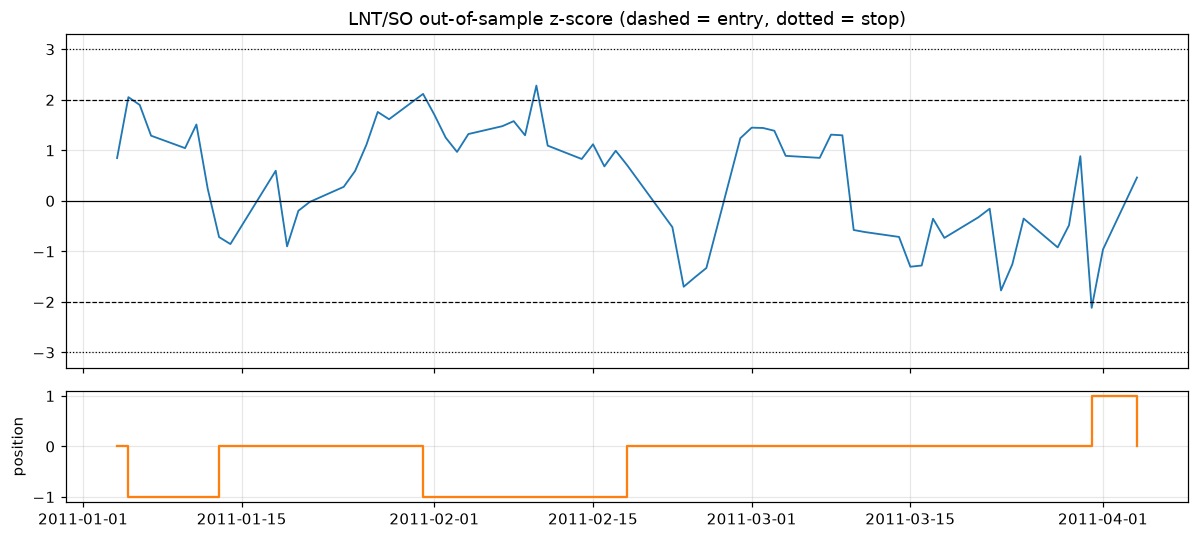

In [6]:
def spread_positions(z, hl, entry=ENTRY_Z, exit_=EXIT_Z, stop=STOP_Z, max_hold_hl=MAX_HOLD_HALF_LIVES):
    """Daily state machine: +1 long spread, -1 short spread, 0 flat. Exits are checked before entries."""
    max_hold = int(np.ceil(max_hold_hl * hl))
    state, held, cooldown = 0, 0, False
    out = np.zeros(len(z))
    for t, zt in enumerate(z):
        if state != 0:
            held += 1
            reverted = (state == 1 and zt >= -exit_) or (state == -1 and zt <= exit_)
            stopped = abs(zt) >= stop or held >= max_hold
            if reverted or stopped:
                state, held, cooldown = 0, 0, stopped
        if cooldown and abs(zt) < entry:
            cooldown = False
        if state == 0 and not cooldown:
            if zt <= -entry:
                state, held = 1, 0
            elif zt >= entry:
                state, held = -1, 0
        out[t] = state
    return out


def pair_zscore(logp, pair, trade_idx, z_hl=Z_WINDOW_HALF_LIVES):
    """Out-of-sample z-score of a pair's spread over `trade_idx`, with frozen alpha/beta and a rolling
    window of z_hl x half-life days (the window's first days come from the formation period)."""
    window = max(5, int(round(z_hl * pair.half_life)))
    i0 = logp.index.get_loc(trade_idx[0])
    sl = slice(i0 - window + 1, i0 + len(trade_idx))
    spread = logp[pair.a].iloc[sl] - pair.alpha - pair.beta * logp[pair.b].iloc[sl]
    z = (spread - spread.rolling(window).mean()) / spread.rolling(window).std()
    return z.loc[trade_idx], spread.loc[trade_idx], window


def leg_weights(beta, capital):
    """Dollar weights of A and B for one unit of 'long the spread' (hedge-ratio sized)."""
    return 2 * capital / (1 + beta), -2 * capital * beta / (1 + beta)


# Example: the first selected pair of the demo window, traded over the next quarter
trade_idx = log_prices.index[FORMATION_WINDOW:FORMATION_WINDOW + TRADING_WINDOW]
ex = demo_selected.iloc[0]
z_ex, spread_ex, win_ex = pair_zscore(log_prices, ex, trade_idx)
pos_ex = spread_positions(z_ex.values, ex.half_life)
print(f"{ex.a}/{ex.b}: beta={ex.beta:.2f}, half-life={ex.half_life:.1f}d -> z window {win_ex}d, "
      f"time stop {int(np.ceil(MAX_HOLD_HALF_LIVES * ex.half_life))}d")
print("legs for 'long the spread' at 1/40 capital:  A = {:+.4f}, B = {:+.4f}".format(*leg_weights(ex.beta, PAIR_CAPITAL)))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(z_ex.index, z_ex, lw=1.2)
for lvl, ls in [(0, "-"), (ENTRY_Z, "--"), (-ENTRY_Z, "--"), (STOP_Z, ":"), (-STOP_Z, ":")]:
    ax1.axhline(lvl, color="k", lw=0.8, ls=ls)
ax1.set_title(f"{ex.a}/{ex.b} out-of-sample z-score (dashed = entry, dotted = stop)")
ax2.step(z_ex.index, pos_ex, where="post", color="C1")
ax2.set_yticks([-1, 0, 1]); ax2.set_ylabel("position")
plt.tight_layout(); plt.show()

---
## Phase 4 — PnL engine

One function turns **daily target weights** (fraction of NAV, decided at each close) and **prices** into a daily
equity curve. Every later result runs through it, so it is tested against a hand calculation before use.

How it works, day by day:

1. **Mark to market.** Yesterday's dollar holdings earn today's return: $\text{PnL}_t = \sum_i h_{i,t-1} r_{i,t}$.
   Holdings then drift with prices (we hold *shares*, not constant weights).
2. **Borrow.** Every short position pays `BORROW_BPS_ANNUAL / 252` per day on its dollar value.
3. **Trade.** For every stock whose *target* changed today, trade to target × NAV. Stocks whose target did not
   change are left alone (no hidden daily rebalancing).
4. **Costs.** Every dollar traded pays commission + half-spread + slippage.

**Timing.** Weights decided at the close of day *t* (using prices up to *t*) are executed at that close
(market-on-close) and first earn the return of day *t+1*. A signal never earns the return of the bar it was
computed on. (Phase 9 also shows the more conservative "execute at the next day's open".)

In [7]:
def run_backtest(weights, prices, cost_bps=COST_BPS, borrow_bps=BORROW_BPS_ANNUAL):
    """Daily target weights (fraction of NAV) + prices -> daily PnL table (NAV starts at 1)."""
    W = weights.reindex(index=prices.index, columns=prices.columns).fillna(0.0).to_numpy()
    R = prices.pct_change().fillna(0.0).to_numpy()
    cost, borrow_daily = cost_bps / 1e4, borrow_bps / 1e4 / TRADING_DAYS

    nav, h, prev_target = 1.0, np.zeros(W.shape[1]), np.zeros(W.shape[1])
    rows = []
    for t in range(len(W)):
        nav_start = nav
        pnl = h @ R[t]                                   # 1) mark to market
        borrow = np.clip(-h, 0, None).sum() * borrow_daily   # 2) borrow on shorts
        h = h * (1 + R[t])
        nav = nav + pnl - borrow
        changed = W[t] != prev_target                    # 3) trade only names whose target changed
        new_h = np.where(changed, W[t] * nav, h)
        traded = np.abs(new_h - h).sum()
        tc = traded * cost                               # 4) costs on dollars traded
        nav -= tc
        h, prev_target = new_h, W[t]
        rows.append((pnl / nav_start, tc / nav_start, borrow / nav_start, traded / nav_start,
                     np.abs(h).sum() / nav, h.sum() / nav))

    out = pd.DataFrame(rows, index=prices.index,
                       columns=["gross_ret", "cost", "borrow", "turnover", "gross_exposure", "net_exposure"])
    out["net_ret"] = out.gross_ret - out.cost - out.borrow
    out["equity"] = (1 + out.net_ret).cumprod()
    out["gross_equity"] = (1 + out.gross_ret).cumprod()
    return out

**Unit test with a known answer** (from `phases.txt`). Stock A goes 100 → 110 and stock B 100 → 95 over three
days. At the close of day 0 we go long $0.50 of A and short $0.50 of B; at the close of day 3 we close both.

By hand:
* Gross PnL: A earns 10% on $0.50 = **+$0.050**, the B short earns 5% on $0.50 = **+$0.025** → **+$0.075**.
* Entry cost: we trade $0.50 + $0.50 = $1.00 → $1.00 × 5 bps.
* Exit cost: A is now worth $0.55 and the B short $0.475 → we trade $1.025 → $1.025 × 5 bps.
* Borrow: on the short's value at the start of each held day: ($0.50 + $0.49 + $0.48) × 50 bps / 252.

In [8]:
idx = pd.date_range("2020-01-01", periods=5, freq="D")
px_test = pd.DataFrame({"A": [100, 104, 107, 110, 110], "B": [100, 98, 96, 95, 95]}, index=idx, dtype=float)
w_test = pd.DataFrame({"A": [0.5, 0.5, 0.5, 0.0, 0.0], "B": [-0.5, -0.5, -0.5, 0.0, 0.0]}, index=idx)
res = run_backtest(w_test, px_test)

c, b = COST_BPS / 1e4, BORROW_BPS_ANNUAL / 1e4 / TRADING_DAYS
gross_pnl = 0.5 * 0.10 + 0.5 * 0.05
cost_total = 1.00 * c + 1.025 * c
borrow_total = (0.50 + 0.49 + 0.48) * b
expected_nav = 1 + gross_pnl - cost_total - borrow_total
engine_nav = res.equity.iloc[-1]

print(f"hand calculation: gross +{gross_pnl:.4f}  costs -{cost_total:.6f}  borrow -{borrow_total:.6f}  -> NAV {expected_nav:.8f}")
print(f"engine:                                                               -> NAV {engine_nav:.8f}")
assert np.isclose(engine_nav, expected_nav, atol=1e-12), "PnL engine disagrees with the hand calculation"
assert np.isclose((res.cost * res.equity.shift(1, fill_value=1)).sum(), cost_total, atol=1e-12)
assert res.gross_ret.iloc[0] == 0, "nothing can be earned on the day the position is opened"
print("PnL engine: all asserts pass")
res.round(6)

hand calculation: gross +0.0750  costs -0.001012  borrow -0.000029  -> NAV 1.07395833
engine:                                                               -> NAV 1.07395833
PnL engine: all asserts pass


,gross_ret,cost,borrow,turnover,gross_exposure,net_exposure,net_ret,equity,gross_equity
2020-01-01,0.000000,0.000500,0.000000,1.000000,1.000500,0.000000,-0.000500,0.999500,1.000000
2020-01-02,0.030015,0.000000,0.000010,0.000000,0.981068,0.029141,0.030005,1.029490,1.030015
2020-01-03,0.024284,0.000000,0.000009,0.000000,0.962559,0.052158,0.024274,1.054480,1.055028
2020-01-04,0.018967,0.000486,0.000009,0.972043,0.000000,0.000000,0.018472,1.073958,1.075038
2020-01-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.073958,1.075038


---
## Phase 5 — Walk-forward loop (pairs)

Roll through history in non-overlapping 63-day steps. At each step:

1. **Form** on the trailing 252 days: Engle-Granger on every sub-industry pair, filter, select ≤ 40 pairs
   (Phase 2). Last quarter's pairs and hedge ratios are thrown away.
2. **Trade** the next 63 days: for each pair, z-score with frozen α/β and the half-life window, state machine,
   hedge-ratio legs, 1/√H capital (Phase 3).
3. **Book** = sum of all pair legs (one stock is in at most one pair, so nothing overlaps).

Concatenating the trading windows gives one continuous out-of-sample weight series; positions open at the end
of a window are closed when the next window starts. One `run_backtest` call produces the equity curve.

In [9]:
def walk_forward_pairs(logp, pairs, formation=FORMATION_WINDOW, trading=TRADING_WINDOW, select_kw=None,
                       entry=ENTRY_Z, z_hl=Z_WINDOW_HALF_LIVES, max_hold_hl=MAX_HOLD_HALF_LIVES,
                       capital=PAIR_CAPITAL, hl_sizing=True, hedge_legs=True, rolling_z=True, selector=None,
                       verbose=False):
    """Returns (weights, trades_info) where trades_info holds, per window, each traded pair with its z and positions.
    The keyword switches exist only so Phase 9.1 can switch each fix off again."""
    select_kw = select_kw or {}
    idx = logp.index
    books, info = [], []
    for k, start in enumerate(range(formation, len(idx), trading)):
        form, trade_idx = logp.iloc[start - formation:start], idx[start:start + trading]
        selected = (selector or select_pairs)(engle_granger_batch(form, pairs), **select_kw)
        book = pd.DataFrame(0.0, index=trade_idx, columns=logp.columns)
        if len(selected):
            size = 1 / np.sqrt(selected.half_life) if hl_sizing else pd.Series(1.0, index=selected.index)
            size = size / size.mean()
            for i, pair in selected.iterrows():
                if rolling_z:
                    z, spread, _ = pair_zscore(logp, pair, trade_idx, z_hl)
                else:   # v1: formation-window mean / std, frozen
                    spread = logp.loc[trade_idx, pair.a] - pair.alpha - pair.beta * logp.loc[trade_idx, pair.b]
                    z = (spread - pair.spread_mean) / pair.spread_std
                pos = spread_positions(z.values, pair.half_life, entry=entry, max_hold_hl=max_hold_hl)
                wa, wb = leg_weights(pair.beta, capital * size[i]) if hedge_legs else (capital * size[i], -capital * size[i])
                book[pair.a] += wa * pos
                book[pair.b] += wb * pos
                info.append(dict(window=k, a=pair.a, b=pair.b, beta=pair.beta, half_life=pair.half_life,
                                 pvalue=pair.pvalue, wa=wa, wb=wb, z=z, spread=spread,
                                 pos=pd.Series(pos, index=trade_idx)))
        books.append(book)
        if verbose and k % 8 == 0:
            print(f"window {k:2d}: trade {trade_idx[0].date()} -> {trade_idx[-1].date()}, {len(selected)} pairs")
    return pd.concat(books), info


t0 = time.time()
pairs_w, pairs_info = walk_forward_pairs(log_prices, PAIRS_SUB, verbose=True)
pairs_bt = run_backtest(pairs_w, prices.loc[pairs_w.index])
print(f"\n{pairs_w.index[0].date()} -> {pairs_w.index[-1].date()}, built in {time.time() - t0:.0f}s")
print(f"average pairs per window: {len(pairs_info) / (len(pairs_w) / TRADING_WINDOW):.1f}")
print(f"average gross exposure {pairs_bt.gross_exposure.mean():.0%} of NAV, average |net exposure| "
      f"{pairs_bt.net_exposure.abs().mean():.1%} of NAV")

window  0: trade 2011-01-04 -> 2011-04-04, 34 pairs


window  8: trade 2013-01-07 -> 2013-04-08, 40 pairs


window 16: trade 2015-01-07 -> 2015-04-08, 34 pairs


window 24: trade 2017-01-06 -> 2017-04-06, 35 pairs


window 32: trade 2019-01-09 -> 2019-04-09, 37 pairs


window 40: trade 2021-01-08 -> 2021-04-09, 40 pairs


window 48: trade 2023-01-10 -> 2023-04-11, 24 pairs


window 56: trade 2025-01-14 -> 2025-04-14, 40 pairs



2011-01-04 -> 2026-09-14, built in 10s
average pairs per window: 36.5
average gross exposure 66% of NAV, average |net exposure| 5.9% of NAV


---
## Phase 6 — Pairs results

The helper functions below compute the standard performance statistics:

* **Sharpe** = mean daily return / std × √252 (risk-free rate ignored: a dollar-neutral book is self-financing).
* **Max drawdown** = worst peak-to-trough fall of the equity curve.
* **Turnover** = dollars traded per year / NAV (both legs counted).
* **Hit rate** = share of closed pair trades with a positive gross PnL.
* **SPY** is shown for scale only — a market-neutral book is not trying to beat the index, it is trying to earn
  a return that is *uncorrelated* with it.

In [10]:
def sharpe(r):
    return r.mean() / r.std() * np.sqrt(TRADING_DAYS) if r.std() > 0 else np.nan


def max_drawdown(r):
    eq = (1 + r).cumprod()
    return (eq / eq.cummax() - 1).min()


def ann_return(r):
    return (1 + r).prod() ** (TRADING_DAYS / len(r)) - 1


def pair_trade_log(info, prices):
    """One row per closed pair trade, with its gross return on the capital committed to the pair."""
    rows = []
    for p in info:
        pos = p["pos"]
        r = prices.loc[pos.index, [p["a"], p["b"]]].pct_change().fillna(0.0)
        daily = pos.shift(1, fill_value=0) * (p["wa"] * r[p["a"]] + p["wb"] * r[p["b"]]) / (abs(p["wa"]) + abs(p["wb"]))
        prev = pos.shift(1, fill_value=0)
        for entry in pos.index[(pos != 0) & (prev != pos)]:
            after = pos.loc[entry:]
            changed = after != after.iloc[0]
            exit_ = changed.idxmax() if changed.any() else after.index[-1]
            side, z_exit = int(pos.loc[entry]), p["z"].loc[exit_]
            if not changed.any():
                reason = "end of window"
            elif abs(z_exit) >= STOP_Z:
                reason = "z-stop"
            elif (side == 1 and z_exit >= -EXIT_Z) or (side == -1 and z_exit <= EXIT_Z):
                reason = "reverted"
            else:
                reason = "time-stop"
            rows.append(dict(window=p["window"], a=p["a"], b=p["b"], side=side, entry=entry, exit=exit_,
                             days=after.index.get_loc(exit_), reason=reason, ret=daily.loc[entry:exit_].iloc[1:].sum()))
    return pd.DataFrame(rows)


def yearly_table(bt, spy_ret, trades=None):
    """Calendar-year performance, gross and net, vs SPY; last row = full period."""
    rows = {}
    for label, chunk in list(bt.groupby(bt.index.year)) + [("ALL", bt)]:
        s = spy_ret.loc[chunk.index]
        row = {"gross ret": ann_return(chunk.gross_ret), "gross Sharpe": sharpe(chunk.gross_ret),
               "net ret": ann_return(chunk.net_ret), "net Sharpe": sharpe(chunk.net_ret),
               "net max DD": max_drawdown(chunk.net_ret),
               "turnover (x/yr)": chunk.turnover.sum() * TRADING_DAYS / len(chunk),
               "days up": (chunk.net_ret > 0).sum() / (chunk.net_ret != 0).sum()}
        if trades is not None:
            t = trades if label == "ALL" else trades[trades.entry.dt.year == label]
            row["trades"] = len(t)
            row["hit rate"] = (t.ret > 0).mean() if len(t) else np.nan
        row.update({"SPY ret": ann_return(s), "SPY Sharpe": sharpe(s)})
        rows[label] = row
    return pd.DataFrame(rows).T


def style_table(df):
    pct = [c for c in df.columns if "ret" in c or "DD" in c or "rate" in c or "days up" in c]
    fmt = {c: "{:+.1%}" for c in pct} | {c: "{:+.2f}" for c in df.columns if "Sharpe" in c}
    fmt |= {c: "{:.0f}" for c in df.columns if c in ("trades", "turnover (x/yr)")}
    return df.style.format(fmt, na_rep="-")


def period_split(r):
    """Sharpe on the development period, the holdout, and both."""
    return pd.Series({"dev 2011-18": sharpe(r.loc[:DEV_END]), "holdout 2019-26": sharpe(r.loc[DEV_END:].iloc[1:]),
                      "full": sharpe(r)})


pairs_trades = pair_trade_log(pairs_info, prices)
pairs_year = yearly_table(pairs_bt, spy_ret, pairs_trades)
style_table(pairs_year)

,gross ret,gross Sharpe,net ret,net Sharpe,net max DD,turnover (x/yr),days up,trades,hit rate,SPY ret,SPY Sharpe
2011,+4.9%,+1.24,+2.6%,+0.68,-3.9%,40,+52.2%,408,+65.9%,+0.9%,+0.15
2012,+9.0%,+3.10,+6.4%,+2.26,-0.9%,44,+55.2%,440,+67.7%,+16.1%,+1.24
2013,+3.5%,+1.44,+1.1%,+0.48,-1.9%,43,+48.4%,431,+61.0%,+32.3%,+2.58
2014,+2.2%,+0.81,-0.2%,-0.07,-3.0%,44,+45.2%,432,+60.4%,+13.5%,+1.18
2015,+4.5%,+1.66,+2.3%,+0.87,-1.7%,39,+51.2%,394,+64.5%,+1.2%,+0.16
2016,-1.6%,-0.56,-3.5%,-1.25,-4.5%,36,+47.2%,366,+62.3%,+12.0%,+0.93
2017,+1.5%,+0.84,-0.6%,-0.33,-1.4%,39,+47.4%,389,+61.7%,+21.8%,+2.96
2018,+3.8%,+1.38,+1.7%,+0.61,-2.9%,39,+47.0%,391,+63.4%,-4.6%,-0.19
2019,+3.5%,+1.44,+1.3%,+0.57,-1.3%,38,+50.0%,380,+62.9%,+31.2%,+2.24
2020,+16.3%,+2.80,+14.1%,+2.45,-2.5%,36,+53.4%,373,+66.8%,+18.3%,+0.67


In [11]:
full = pairs_year.loc["ALL"]
X = np.column_stack([np.ones(len(pairs_bt)), spy_ret.loc[pairs_bt.index]])
pairs_beta = np.linalg.lstsq(X, pairs_bt.net_ret.to_numpy(), rcond=None)[0][1]
print(f"PAIRS, {pairs_bt.index[0].date()} -> {pairs_bt.index[-1].date()}, costs {COST_BPS:.0f} bps + borrow")
print(f"  net Sharpe {full['net Sharpe']:+.2f} (gross {full['gross Sharpe']:+.2f})   net return {full['net ret']:+.1%}/yr "
      f"at {pairs_bt.gross_exposure.mean():.0%} average gross exposure")
print(f"  max drawdown {full['net max DD']:.1%}   turnover {full['turnover (x/yr)']:.0f}x/yr   "
      f"hit rate {full['hit rate']:.0%} over {full['trades']:.0f} trades   beta to SPY {pairs_beta:+.3f}")
print("  Sharpe by period (net):", period_split(pairs_bt.net_ret).round(2).to_dict())
print("  Sharpe by period (gross):", period_split(pairs_bt.gross_ret).round(2).to_dict())
print("\nHow trades end:")
print(pairs_trades.groupby("reason").ret.agg(trades="count", avg_ret=lambda r: f"{r.mean():+.2%}",
                                              hit_rate=lambda r: f"{(r > 0).mean():.0%}").to_string())

PAIRS, 2011-01-04 -> 2026-09-14, costs 5 bps + borrow
  net Sharpe +0.50 (gross +1.14)   net return +1.6%/yr at 66% average gross exposure
  max drawdown -6.3%   turnover 39x/yr   hit rate 63% over 6104 trades   beta to SPY +0.037
  Sharpe by period (net): {'dev 2011-18': 0.44, 'holdout 2019-26': 0.56, 'full': 0.5}
  Sharpe by period (gross): {'dev 2011-18': 1.23, 'holdout 2019-26': 1.1, 'full': 1.14}

How trades end:
               trades avg_ret hit_rate
reason                                
end of window     855  -1.07%      25%
reverted         4726  +0.89%      76%
time-stop         341  -4.60%       0%
z-stop            182  -2.46%      10%


**Plots: equity curve and drawdown.** Note the left axis: the strategy's NAV is on a much smaller scale than
SPY's, because a market-neutral book does not ride the market. Sharpe ratio (return per unit of risk) and the
beta are the numbers to compare; the absolute return can be scaled with leverage (Phase 10 shows the book
scaled to 10% volatility).

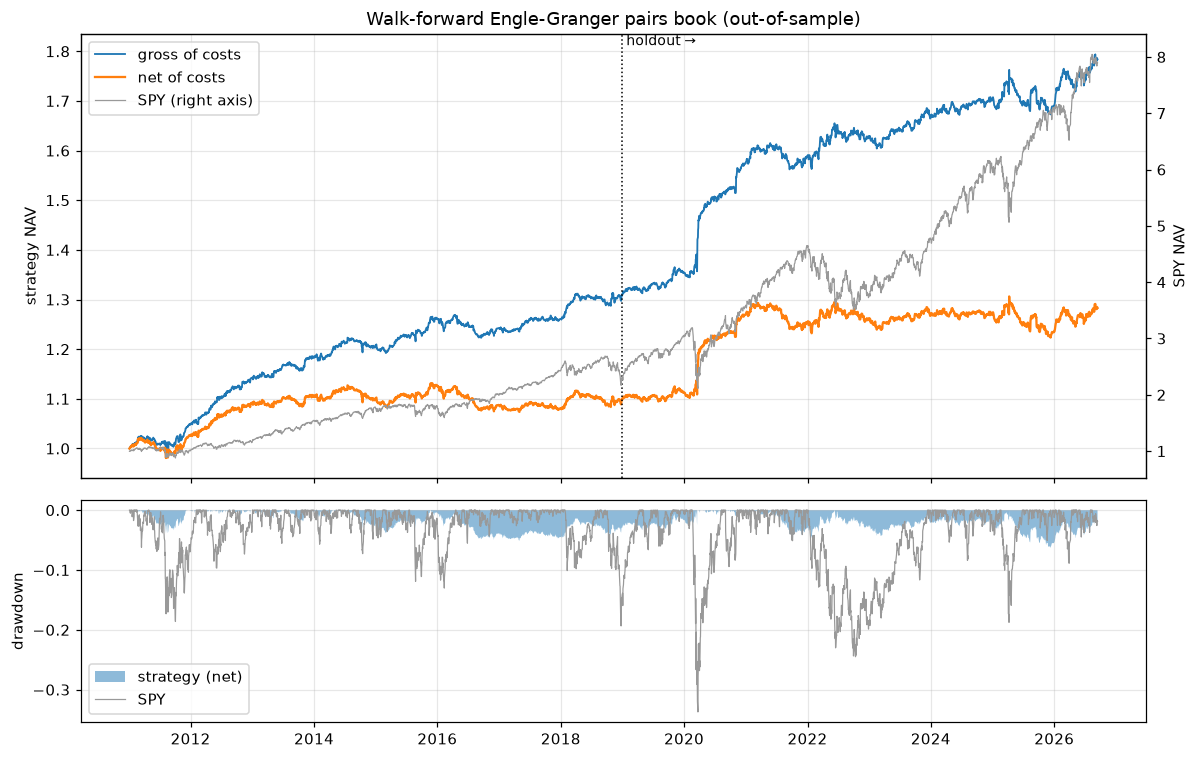

In [12]:
def plot_equity(bt, title, spy_ret):
    spy_eq = (1 + spy_ret.loc[bt.index]).cumprod()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax1.plot(bt.index, bt.gross_equity, label="gross of costs", lw=1.2)
    ax1.plot(bt.index, bt.equity, label="net of costs", lw=1.5)
    ax1b = ax1.twinx()
    ax1b.plot(spy_eq.index, spy_eq, color="0.6", lw=0.8, label="SPY (right axis)")
    ax1b.grid(False)
    ax1.axvline(pd.Timestamp(DEV_END), color="k", ls=":", lw=1)
    ax1.text(pd.Timestamp(DEV_END), ax1.get_ylim()[1], " holdout →", va="top", fontsize=9)
    ax1.set_ylabel("strategy NAV"); ax1b.set_ylabel("SPY NAV")
    ax1.set_title(title)
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax1b.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")
    ax2.fill_between(bt.index, bt.equity / bt.equity.cummax() - 1, 0, alpha=0.5, label="strategy (net)")
    ax2.plot(spy_eq.index, spy_eq / spy_eq.cummax() - 1, color="0.6", lw=0.8, label="SPY")
    ax2.set_ylabel("drawdown"); ax2.legend(loc="lower left")
    plt.tight_layout(); plt.show()


plot_equity(pairs_bt, "Walk-forward Engle-Granger pairs book (out-of-sample)", spy_ret)

**One representative pair.** The pair/window with the most round trips, so every kind of entry and exit shows.
Top: the spread (frozen α, β) with its rolling fair level and ±2σ / ±3σ bands. Bottom: the position.

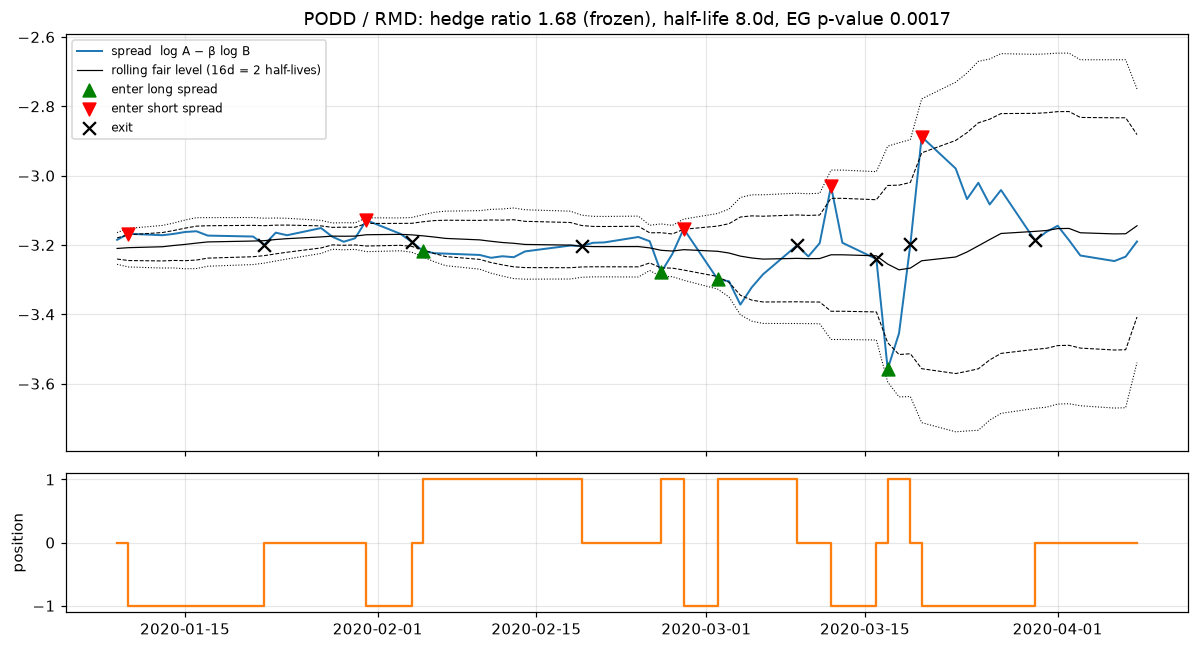

,window,a,b,side,entry,exit,days,reason,ret
3649,36,PODD,RMD,-1,2020-01-10,2020-01-22,7,reverted,0.011793
3650,36,PODD,RMD,-1,2020-01-31,2020-02-04,2,reverted,0.023609
3651,36,PODD,RMD,1,2020-02-05,2020-02-19,9,reverted,0.005431
3652,36,PODD,RMD,1,2020-02-26,2020-02-28,2,reverted,0.046965
3653,36,PODD,RMD,-1,2020-02-28,2020-03-02,1,reverted,0.055215
3654,36,PODD,RMD,1,2020-03-02,2020-03-09,5,reverted,0.034182
3655,36,PODD,RMD,-1,2020-03-12,2020-03-16,2,reverted,0.077525
3656,36,PODD,RMD,1,2020-03-17,2020-03-19,2,reverted,0.130548
3657,36,PODD,RMD,-1,2020-03-20,2020-03-30,6,reverted,0.117966


In [13]:
busiest = pairs_trades.groupby(["window", "a", "b"]).size().idxmax()
rep = next(p for p in pairs_info if (p["window"], p["a"], p["b"]) == busiest)
win = max(5, int(round(Z_WINDOW_HALF_LIVES * rep["half_life"])))
i0 = log_prices.index.get_loc(rep["pos"].index[0])
sp_full = (log_prices[rep["a"]] - rep["beta"] * log_prices[rep["b"]]).iloc[i0 - win + 1:i0 + len(rep["pos"])]
mid, sd = sp_full.rolling(win).mean().loc[rep["pos"].index], sp_full.rolling(win).std().loc[rep["pos"].index]
sp = sp_full.loc[rep["pos"].index]
pos, prev = rep["pos"], rep["pos"].shift(1, fill_value=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(sp.index, sp, color="C0", lw=1.3, label="spread  log A − β log B")
ax1.plot(mid.index, mid, color="k", lw=0.8, label=f"rolling fair level ({win}d = 2 half-lives)")
for n, ls in [(ENTRY_Z, "--"), (STOP_Z, ":")]:
    ax1.plot(mid.index, mid + n * sd, color="k", lw=0.7, ls=ls); ax1.plot(mid.index, mid - n * sd, color="k", lw=0.7, ls=ls)
for mask, mk, col, lab in [((pos == 1) & (prev != 1), "^", "green", "enter long spread"),
                           ((pos == -1) & (prev != -1), "v", "red", "enter short spread"),
                           ((pos == 0) & (prev != 0), "x", "k", "exit")]:
    ax1.scatter(sp.index[mask], sp[mask], marker=mk, color=col, s=70, zorder=5, label=lab)
ax1.set_title(f"{rep['a']} / {rep['b']}: hedge ratio {rep['beta']:.2f} (frozen), half-life {rep['half_life']:.1f}d, "
              f"EG p-value {rep['pvalue']:.4f}")
ax1.legend(fontsize=8, loc="best")
ax2.step(pos.index, pos, where="post", color="C1"); ax2.set_yticks([-1, 0, 1]); ax2.set_ylabel("position")
plt.tight_layout(); plt.show()
pairs_trades[(pairs_trades.window == busiest[0]) & (pairs_trades.a == busiest[1]) & (pairs_trades.b == busiest[2])]

---
## Phase 9 — Robustness (pairs book)

Four questions:

1. **Did each fix actually help?** Start from the previous version's rules on the same data and switch the fixes
   on one at a time.
2. **Is the result a knife-edge?** Vary entry threshold, formation length and cost.
3. **Is there leakage?** Replace the signals with random ones of the same frequency; the result should be ≈ 0
   gross and negative net.
4. **Does anything survive post-2015, and with slower execution?**

### 9.1 From the previous version to this one, one fix at a time (5 bps costs)

In [14]:
PAIRS_SECTOR = candidate_pairs(SECTOR)


def naive_adf_selection(table, **kw):
    """The previous version's mistake: ordinary ADF p-values (N=1) instead of Engle-Granger ones."""
    t = table.copy()
    t["pvalue"] = [mackinnonp(x, regression="c", N=1) if x < -1.0 else 1.0 for x in t.adf_t]
    return select_pairs(t, **kw)


def run_variant(pairs, naive=False, max_pairs=MAX_PAIRS, per_stock=MAX_PAIRS_PER_STOCK, **kw):
    sel_kw = dict(max_pairs=max_pairs, max_per_stock=per_stock)
    w, _ = walk_forward_pairs(log_prices, pairs, select_kw=sel_kw, capital=1 / max_pairs,
                              selector=naive_adf_selection if naive else select_pairs, **kw)
    bt = run_backtest(w, prices.loc[w.index])
    return {"gross Sharpe": sharpe(bt.gross_ret), "net Sharpe": sharpe(bt.net_ret),
            "net dev": sharpe(bt.net_ret.loc[:DEV_END]), "net holdout": sharpe(bt.net_ret.loc[DEV_END:].iloc[1:]),
            "net ret/yr": ann_return(bt.net_ret), "turnover": bt.turnover.mean() * TRADING_DAYS}


v1_rules = dict(max_pairs=20, per_stock=None, rolling_z=False, hedge_legs=False, max_hold_hl=2, hl_sizing=False)
steps = [
    ("previous rules (sector pairs, naive ADF, frozen mean, equal legs, 20 pairs)", dict(pairs=PAIRS_SECTOR, naive=True, **v1_rules)),
    ("+ Engle-Granger critical values", dict(pairs=PAIRS_SECTOR, **v1_rules)),
    ("+ sub-industry pairs", dict(pairs=PAIRS_SUB, **v1_rules)),
    ("+ one pair per stock, 40 slots", dict(pairs=PAIRS_SUB, **(v1_rules | dict(max_pairs=40, per_stock=1)))),
    ("+ rolling z-score (2 half-lives)", dict(pairs=PAIRS_SUB, **(v1_rules | dict(max_pairs=40, per_stock=1, rolling_z=True)))),
    ("+ hedge-ratio legs", dict(pairs=PAIRS_SUB, **(v1_rules | dict(max_pairs=40, per_stock=1, rolling_z=True, hedge_legs=True)))),
    ("+ time stop 3 half-lives", dict(pairs=PAIRS_SUB, **(v1_rules | dict(max_pairs=40, per_stock=1, rolling_z=True, hedge_legs=True, max_hold_hl=3)))),
    ("+ capital ∝ 1/√half-life  (= this notebook)", dict(pairs=PAIRS_SUB)),
]
t0 = time.time()
ablation = pd.DataFrame({label: run_variant(**kw) for label, kw in steps}).T
print(f"{time.time() - t0:.0f}s")
ablation.style.format({c: "{:+.2f}" for c in ["gross Sharpe", "net Sharpe", "net dev", "net holdout"]}
                      | {"net ret/yr": "{:+.1%}", "turnover": "{:.0f}x"})

186s


,gross Sharpe,net Sharpe,net dev,net holdout,net ret/yr,turnover
"previous rules (sector pairs, naive ADF, frozen mean, equal legs, 20 pairs)",+0.17,-0.25,-0.41,-0.10,-0.8%,25x
+ Engle-Granger critical values,+0.17,-0.25,-0.41,-0.10,-0.8%,25x
+ sub-industry pairs,+0.26,-0.22,-0.55,+0.05,-0.6%,24x
"+ one pair per stock, 40 slots",+0.48,-0.11,-0.45,+0.18,-0.2%,21x
+ rolling z-score (2 half-lives),+1.11,+0.35,+0.19,+0.49,+1.0%,40x
+ hedge-ratio legs,+1.07,+0.43,+0.31,+0.52,+1.4%,40x
+ time stop 3 half-lives,+1.14,+0.52,+0.41,+0.61,+1.7%,39x
+ capital ∝ 1/√half-life (= this notebook),+1.14,+0.50,+0.44,+0.56,+1.6%,39x


### 9.2 Sensitivity: entry threshold × formation length × cost (net Sharpe from 2012)

In [15]:
t0 = time.time()
sens = {}
for formation in (126, 252, 504):
    for entry in (1.5, 2.0, 2.5):
        w, _ = walk_forward_pairs(log_prices, PAIRS_SUB, formation=formation, entry=entry)
        w = w.loc["2012-01-01":]          # common start so formation lengths are comparable
        for cost in (0, 3, 5, 10):
            sens[(formation, entry, cost)] = sharpe(run_backtest(w, prices.loc[w.index], cost_bps=cost).net_ret)
sens = pd.Series(sens).unstack([2]).rename(index=lambda v: f"{v:g}")
sens.index.names, sens.columns.name = ["formation days", "entry |z|"], "cost bps →"
print(f"{time.time() - t0:.0f}s   (net Sharpe from 2012; base case = 252 / 2.0 / 5 bps)")
sens.style.format("{:+.2f}").background_gradient(cmap="RdYlGn", vmin=-1, vmax=1)

97s   (net Sharpe from 2012; base case = 252 / 2.0 / 5 bps)


**Break-even cost.** Net Sharpe as the all-in cost per dollar traded goes from 0 to 10 bps. Where the line crosses
zero is the most you could pay per trade and still make money.

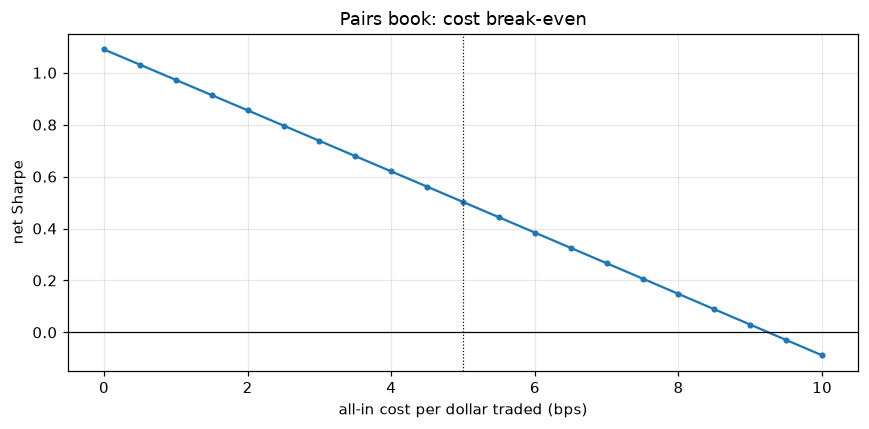

break-even cost: 9.3 bps per dollar traded (base case 5 bps)


In [16]:
cost_grid = np.arange(0, 10.5, 0.5)
breakeven_curve = pd.Series([sharpe(run_backtest(pairs_w, prices.loc[pairs_w.index], cost_bps=c).net_ret) for c in cost_grid],
                            index=cost_grid)
breakeven = float(np.interp(0, -breakeven_curve.to_numpy(), cost_grid))
ax = breakeven_curve.plot(figsize=(8, 4), marker=".")
ax.axhline(0, color="k", lw=0.8); ax.axvline(COST_BPS, color="k", ls=":", lw=0.8)
ax.set_xlabel("all-in cost per dollar traded (bps)"); ax.set_ylabel("net Sharpe"); ax.set_title("Pairs book: cost break-even")
plt.tight_layout(); plt.show()
print(f"break-even cost: {breakeven:.1f} bps per dollar traded (base case {COST_BPS:.0f} bps)")

### 9.3 Leakage check: random signals with the same trading frequency

Keep every pair's position path (same number, length and timing of trades), but shift it in time by a random
amount inside its window and flip its direction at random. If this "random" book earned money gross, the engine or
the data would be leaking future information.

In [17]:
rand_rows = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    w_rand = pd.DataFrame(0.0, index=pairs_w.index, columns=pairs_w.columns)
    for p in pairs_info:
        pos = np.roll(p["pos"].to_numpy(), rng.integers(len(p["pos"]))) * rng.choice([-1, 1])
        w_rand.loc[p["pos"].index, p["a"]] += p["wa"] * pos
        w_rand.loc[p["pos"].index, p["b"]] += p["wb"] * pos
    bt_p = run_backtest(w_rand, prices.loc[w_rand.index])
    rand_rows.append({"gross Sharpe": sharpe(bt_p.gross_ret), "net Sharpe": sharpe(bt_p.net_ret)})
rand = pd.DataFrame(rand_rows, index=[f"random seed {s}" for s in range(5)])
rand.loc["mean of random"] = rand.mean()
rand.loc["real signal"] = [sharpe(pairs_bt.gross_ret), sharpe(pairs_bt.net_ret)]
rand.style.format("{:+.2f}")

,gross Sharpe,net Sharpe
random seed 0,+0.43,-0.45
random seed 1,-0.07,-0.96
random seed 2,-0.37,-1.23
random seed 3,-0.05,-0.97
random seed 4,-0.27,-1.14
mean of random,-0.07,-0.95
real signal,+1.14,+0.50


### 9.4 Post-2015, and execution one step later

The market-on-close assumption (signal computed with the close, traded at the close) is standard in the
literature, but in practice you'd compute the signal a few minutes before the close. The harshest alternative is
to trade at the **next day's open**: we feed the engine opening prices and lag the weights one day.

In [18]:
def ex_row(w, px_, lag=0):
    w = w.shift(lag).fillna(0) if lag else w
    bt = run_backtest(w, px_.loc[w.index])
    return {"net Sharpe": sharpe(bt.net_ret), "net Sharpe 2016+": sharpe(bt.net_ret.loc["2016":]),
            "net holdout": sharpe(bt.net_ret.loc[DEV_END:].iloc[1:]), "gross Sharpe": sharpe(bt.gross_ret)}


timing = pd.DataFrame({"trade at close t (base)": ex_row(pairs_w, prices),
                       "trade at open t+1": ex_row(pairs_w, opens, lag=1)}).T
timing.style.format("{:+.2f}")

,net Sharpe,net Sharpe 2016+,net holdout,gross Sharpe
trade at close t (base),+0.50,+0.37,+0.56,+1.14
trade at open t+1,+0.24,+0.13,+0.32,+0.87


---
## Phase 10 — Conclusions (pairs book)

The summary below is printed from the numbers computed above, so it always matches the notebook. The daily
results are also saved to `data/pairs_results.pkl` so Part 2 can compare the cross-sectional book against them.

In [19]:
pairs_bt.to_pickle(DATA_DIR / "pairs_results.pkl")
vol = pairs_bt.net_ret.std() * np.sqrt(TRADING_DAYS)
print(f"""PAIRS BOOK  {pairs_bt.index[0].date()} -> {pairs_bt.index[-1].date()}, {COST_BPS:.0f} bps per dollar traded + {BORROW_BPS_ANNUAL:.0f} bps/yr borrow

  net Sharpe {sharpe(pairs_bt.net_ret):+.2f}  (development {sharpe(pairs_bt.net_ret.loc[:DEV_END]):+.2f}, holdout {sharpe(pairs_bt.net_ret.loc[DEV_END:].iloc[1:]):+.2f});  gross {sharpe(pairs_bt.gross_ret):+.2f}
  {ann_return(pairs_bt.net_ret):+.1%}/yr at {pairs_bt.gross_exposure.mean():.0%} average gross exposure;  {ann_return(pairs_bt.net_ret * 0.10 / vol):+.1%}/yr if scaled to 10% vol
  beta to SPY {pairs_beta:+.3f};  max drawdown {max_drawdown(pairs_bt.net_ret):.1%};  previous rules on the same data: net Sharpe {ablation.iloc[0]['net Sharpe']:+.2f}
  break-even cost {breakeven:.1f} bps;  post-2015 net Sharpe {timing.loc['trade at close t (base)', 'net Sharpe 2016+']:+.2f};  random-signal gross Sharpe {rand.loc['mean of random', 'gross Sharpe']:+.2f} (should be ~0)""")

PAIRS BOOK  2011-01-04 -> 2026-09-14, 5 bps per dollar traded + 50 bps/yr borrow

  net Sharpe +0.50  (development +0.44, holdout +0.56);  gross +1.14
  +1.6%/yr at 66% average gross exposure;  +4.6%/yr if scaled to 10% vol
  beta to SPY +0.037;  max drawdown -6.3%;  previous rules on the same data: net Sharpe -0.25
  break-even cost 9.3 bps;  post-2015 net Sharpe +0.37;  random-signal gross Sharpe -0.07 (should be ~0)


### What the results say

Run with the previous version's rules on the same 16 years of data, the textbook strategy loses money (Phase 9.1). The
turnaround comes from changes that can each be justified before looking at any result:

* **The spread's fair level is re-measured over 2 half-lives while the hedge ratio stays frozen.** This is the
  largest single gain. The previous version assumed the spread would come back to last year's average, and it usually didn't.
* **Pairs come from the same sub-industry, each stock is used once, and there are 40 slots.** This gives more
  bets, and more independent ones.
* **Legs are sized with the hedge ratio, the time stop is 3 half-lives, and capital goes to faster spreads.**
  Each of these adds a little.

The result is a moderate edge: a net Sharpe of about 0.5 at 5 bps, similar in the development and holdout
periods, with ~0 market beta and a single-digit drawdown. Three weaknesses are shown rather than hidden. Profits
are lumpy: 2020 (the COVID dislocation) contributes about half of the cumulative net profit, and 2021–2025 are
flat to slightly negative net of costs (about −3% in total), so the post-2015 net Sharpe is only ~0.4. It is
sensitive to the formation length (one year works; six months and two years are much weaker). It is also
sensitive to execution speed: trading at the next open instead of the close loses about a quarter of the gross
Sharpe and half of the net.

**Data-mining disclosure.** About 40 pair variants were tried while developing this notebook. Choices were made on the 2011–2018 numbers, but the holdout numbers were printed alongside them, so the
holdout is not perfectly untouched. Treat the holdout Sharpe as optimistic. Survivorship bias in the universe
works in the same direction.

### What this backtest doesn't capture

Intraday price impact and adverse selection (a resting order gets filled precisely when the price is moving against
it), borrow availability and recalls on specific names (the 50 bps fee assumes everything is easy to borrow),
slippage beyond the flat 2 bps on less liquid pairs, and survivorship bias in the universe (current constituents
only). Results also assume market-on-close execution at the closing price used to compute the signal.

### What would change with real execution data

The fixed half-spread and slippage would be replaced by measured trade-by-trade fill quality (implementation
shortfall), costs would scale with order size relative to average daily volume, position limits would be set as a
fraction of ADV rather than a fixed capital per pair, and the signal would be computed from prices a few minutes before the
close so that market-on-close orders are actually feasible.